# 미국 은행 수익성·리스크 분석 실습

자산 규모별 수익성을 비교하고, 예대율과 자본비율이 함께 움직이는지 살펴본다.

`fdic_2025_q3.csv`를 노트북과 같은 폴더에 두고 위에서부터 실행한다.
패키지가 없다면 코드 셀에서 `%pip install pandas matplotlib scipy`를 한 번 실행한다.

## 1. 데이터 불러오기와 점검

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

csv_path = Path("fdic_2025_q3.csv")
if not csv_path.is_file():
    raise FileNotFoundError(
        f"CSV를 찾을 수 없습니다. 이 위치에 파일을 두거나 csv_path를 수정하세요. {csv_path.resolve()}"
    )

df = pd.read_csv(csv_path, low_memory=False)
print("행과 열 개수:", df.shape)
print("완전히 같은 행:", df.duplicated().sum())
print("전체가 비어 있는 열:", df.isna().all().sum())
df[["NAME", "ASSET", "ROA", "ROE", "NIMY"]].head()

행과 열 개수: (4388, 161)
완전히 같은 행: 0
전체가 비어 있는 열: 8


,NAME,ASSET,ROA,ROE,NIMY
0,STATE STREET BANK&TRUST CO,366079000,0.836410,10.72,1.076821
1,AUBURNBANK,1010662,0.765590,9.26,3.246569
2,ROBERTSON BANKING CO,475520,2.019137,20.72,4.240441
3,PHENIX-GIRARD BANK,327235,0.903777,82.92,2.751847
4,BANK OF EVERGREEN,76420,0.654286,6.42,3.283450


## 2. ROA 극단값과 평균의 민감도

ROA는 자산 대비 순이익 비율이다. 실습에서는 ROA 1위인 FDS BANK를 제외하자
평균이 1.30%에서 1.19%로 낮아졌고, 중앙값은 소수 둘째 자리까지 1.10%였다.

In [2]:
roa = df["ROA"]
top5 = df.nlargest(5, "ROA")[["NAME", "ASSET", "ROA"]]
without_top = roa.drop(index=top5.index[:1])

print(f"ROA 평균: {roa.mean():.2f}%")
print(f"ROA 중앙값: {roa.median():.2f}%")
print(f"ROA가 음수인 은행: {(roa < 0).sum():,}곳")
print(f"1위 제외 후 ROA 평균: {without_top.mean():.2f}%")
print(f"1위 제외 후 ROA 중앙값: {without_top.median():.2f}%")
top5

ROA 평균: 1.30%
ROA 중앙값: 1.10%
ROA가 음수인 은행: 227곳
1위 제외 후 ROA 평균: 1.19%
1위 제외 후 ROA 중앙값: 1.10%


,NAME,ASSET,ROA
3686,FDS BANK,70140,503.053357
3861,CAPITAL BANK&TRUST CO,223566,65.034557
2571,BOSTON TRUST WALDEN CO,93320,41.585113
3887,SEI PRIVATE TRUST CO,250341,41.509085
3942,NORTHWESTERN MUTUAL WEALTH M,587491,33.508320


## 3. 자산 규모별 수익성

`ASSET`은 천 달러 단위다. ROE는 자기자본 대비 순이익, NIM은 이자수익자산 대비 순이자이익을 나타낸다.

In [3]:
df["assets_billion"] = df["ASSET"] / 1_000_000
df["bank_size"] = pd.cut(
    df["assets_billion"],
    bins=[0, 1, 10, 100, float("inf")],
    labels=["Under $1B", "$1B–<$10B", "$10B–<$100B", "$100B and above"],
    right=False,
)

size_summary = df.groupby("bank_size", observed=True).agg(
    Banks=("NAME", "size"),
    Median_ROA=("ROA", "median"),
    Median_ROE=("ROE", "median"),
    Median_NIM=("NIMY", "median"),
)
size_summary.round(2)

C:\Users\xxxxk\AppData\Local\Temp\ipykernel_24400\2894949740.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["assets_billion"] = df["ASSET"] / 1_000_000
C:\Users\xxxxk\AppData\Local\Temp\ipykernel_24400\2894949740.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["bank_size"] = pd.cut(


,Banks,Median_ROA,Median_ROE,Median_NIM
bank_size,,,,
Under $1B,3331,1.10,10.94,3.75
$1B–<$10B,900,1.10,11.18,3.55
$10B–<$100B,127,1.06,9.54,3.36
$100B and above,30,1.14,11.72,3.04


## 4. 예대율과 자본비율의 0 처리

`LNLSDEPR`은 예금 대비 대출·리스 비율이다. `RBCRWAJ`는 위험가중자산 대비 총규제자본 비율이다.
0으로 기록된 값의 의미는 확인이 필요하므로, 포함한 경우와 제외한 경우를 둘 다 계산한다.

In [4]:
loan_to_deposit = df["LNLSDEPR"].dropna()
capital_ratio = df["RBCRWAJ"].dropna()
zero_mask = capital_ratio.eq(0)

print(f"예대율 중앙값: {loan_to_deposit.median():.2f}%")
print(f"예대율 100% 초과: {(loan_to_deposit > 100).sum():,}곳")
print(f"자본비율 결측: {df['RBCRWAJ'].isna().sum():,}곳")
print(f"자본비율 0 기록: {zero_mask.sum():,}곳 ({zero_mask.mean():.1%})")
print(f"0 포함 자본비율 중앙값: {capital_ratio.median():.2f}%")
print(f"0 제외 자본비율 중앙값: {capital_ratio[~zero_mask].median():.2f}%")

예대율 중앙값: 79.76%
예대율 100% 초과: 452곳
자본비율 결측: 0곳
자본비율 0 기록: 1,720곳 (39.2%)
0 포함 자본비율 중앙값: 12.93%
0 제외 자본비율 중앙값: 15.53%


## 5. 스피어만 순위상관

두 지표의 순위가 함께 움직이는 정도를 계산한다.

In [ ]:
metrics = df[["ROA", "ROE", "NIMY", "LNLSDEPR", "RBCRWAJ"]]
corr_all = metrics.corr(method="spearman")

risk_metrics = metrics.copy()
risk_metrics["RBCRWAJ"] = risk_metrics["RBCRWAJ"].where(
    risk_metrics["RBCRWAJ"].ne(0)
)
corr = risk_metrics.corr(method="spearman")

print(f"예대율·자본비율 상관계수 (0 포함): {corr_all.loc['LNLSDEPR', 'RBCRWAJ']:.2f}")
print(f"예대율·자본비율 상관계수 (0 제외): {corr.loc['LNLSDEPR', 'RBCRWAJ']:.2f}")
corr_all.round(2)

## 6. 예대율과 자본비율 산점도

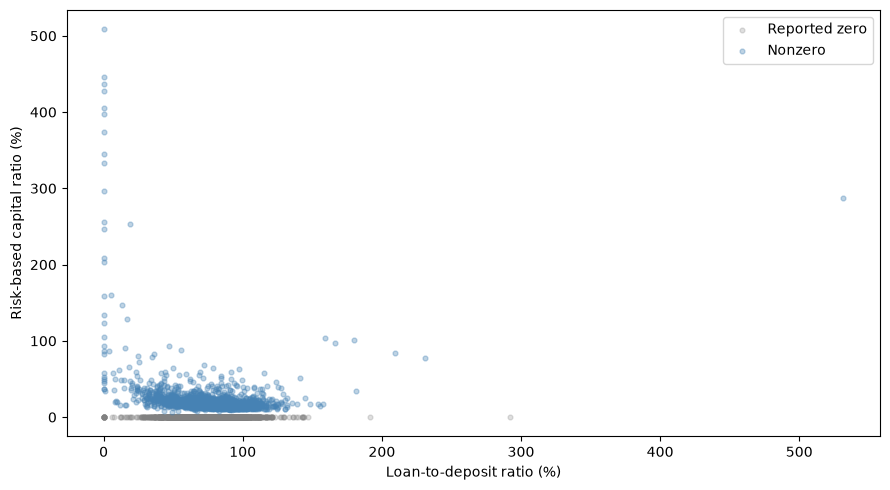

In [5]:
plot_data = df[["LNLSDEPR", "RBCRWAJ"]].dropna()
zero_capital = plot_data["RBCRWAJ"].eq(0)

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(
    plot_data.loc[zero_capital, "LNLSDEPR"],
    plot_data.loc[zero_capital, "RBCRWAJ"],
    color="gray", alpha=0.25, s=12, label="Reported zero",
)
ax.scatter(
    plot_data.loc[~zero_capital, "LNLSDEPR"],
    plot_data.loc[~zero_capital, "RBCRWAJ"],
    color="steelblue", alpha=0.35, s=12, label="Nonzero",
)
ax.set(xlabel="Loan-to-deposit ratio (%)", ylabel="Risk-based capital ratio (%)")
ax.legend()
fig.tight_layout()
plt.show()

## 7. 자산 규모별 예대율·자본비율 순위상관

자본비율이 0인 행을 제외하고, 각 규모 그룹의 은행 수와 상관계수를 함께 확인한다.

In [ ]:
risk_data = df[["bank_size", "LNLSDEPR", "RBCRWAJ"]].dropna()
risk_data = risk_data.loc[risk_data["RBCRWAJ"].ne(0)]

for size, banks in risk_data.groupby("bank_size", observed=True):
    coefficient = banks["LNLSDEPR"].corr(banks["RBCRWAJ"], method="spearman")
    print(f"{size} | 은행 {len(banks):,}곳 | 상관계수 {coefficient:.2f}")

## 8. 예대율과 ROA 산점도

그래프에서는 두 지표 각각의 1~99백분위 범위에 들어가는 점을 그린다.

In [ ]:
plot_risk = df.loc[
    df["LNLSDEPR"].gt(0) & df["ROA"].notna(),
    ["LNLSDEPR", "ROA"],
]
x_low, x_high = plot_risk["LNLSDEPR"].quantile([0.01, 0.99])
y_low, y_high = plot_risk["ROA"].quantile([0.01, 0.99])
plot_risk = plot_risk.loc[
    plot_risk["LNLSDEPR"].between(x_low, x_high)
    & plot_risk["ROA"].between(y_low, y_high)
]

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(plot_risk["LNLSDEPR"], plot_risk["ROA"], alpha=0.4, s=15)
ax.set(title="Loan-to-Deposit Ratio vs. ROA",
       xlabel="Loan-to-deposit ratio (%)", ylabel="ROA (%)")
fig.tight_layout()
plt.show()

## 9. 스피어만 상관계수 히트맵

자본비율이 포함된 비교에서만 자본비율 0을 결측 처리한다.

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
heatmap = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=35, ha="right")
ax.set_yticks(range(len(corr)), corr.index)

for row in range(len(corr)):
    for col in range(len(corr)):
        value = corr.iloc[row, col]
        ax.text(col, row, f"{value:.2f}", ha="center", va="center",
                color="white" if abs(value) > 0.65 else "black")

ax.set_title("Bank Profitability & Risk Correlations")
fig.colorbar(heatmap, ax=ax)
fig.tight_layout()
plt.show()

## 10. 규모별 최종 요약

최종 표의 자본비율 중앙값에는 0으로 기록된 은행을 포함한다.

In [ ]:
funding_summary = df.groupby("bank_size", observed=True).agg(
    Median_Loan_Deposit=("LNLSDEPR", "median"),
    Median_Capital_Ratio=("RBCRWAJ", "median"),
)
summary = size_summary.join(funding_summary)
summary.round(2)

In [ ]:
ax = summary[["Median_ROA", "Median_ROE", "Median_NIM"]].plot.bar(
    figsize=(10, 5), rot=0, title="Bank Profitability by Asset Size"
)
ax.set(xlabel="Asset size", ylabel="Profitability (%)")
ax.figure.tight_layout()
plt.show()

### 참고 자료

[원본 GitHub 프로젝트](https://github.com/marivrnina/us-bank-financial-performance-analysis).
이 실습에서는 원본 분석을 따라가며 ROA 1위 제외 전후 비교, 예대율·자본비율 산점도,
자산 규모별 순위상관 검증을 추가했다. 단일 시점의 상관관계로 인과관계를 판단할 수 없다.